In [11]:
from dotenv import dotenv_values
from openai import OpenAI
from IPython.display import Markdown, Image
import base64
import instructor
from pydantic import BaseModel

In [12]:
env = dotenv_values("../../.env")
openai_client = OpenAI(api_key=env["OPENAI_API_KEY"])

In [13]:
def prepare_image_for_open_ai(image_path):
    with open(image_path, "rb") as f:
        image_data = base64.b64encode(f.read()).decode('utf-8')

    return f"data:image/png;base64,{image_data}"

In [ ]:
# def prepare_image_for_open_ai(image_path):
#     with open(image_path, "rb") as f:
#         image_bytes = f.read()

#     image_data = base64.b64encode(image_bytes).decode('utf-8')

#     return f"data:image/png;base64,{image_data}"

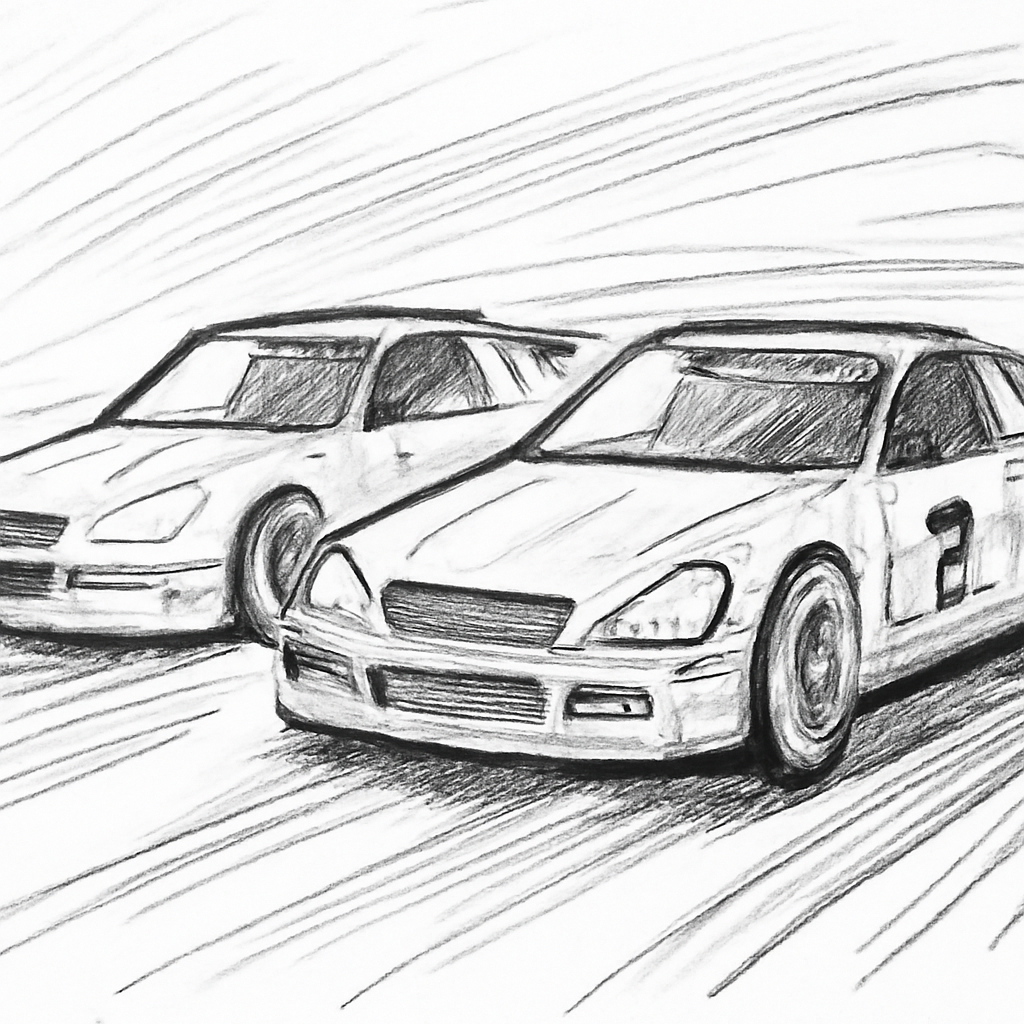

In [14]:
Image("wygenerowany_obrazek.png")

In [15]:
instructor_openai_client = instructor.from_openai(openai_client)

In [16]:
class ImageInfo(BaseModel):
    number_of_people: int
    number_of_cats: int
    number_of_dogs: int
    allowed_for_children: bool

info = instructor_openai_client.chat.completions.create(
    model="gpt-4o-mini",
    response_model=ImageInfo,
    messages=[
        {
            "role": "user",
            "content": [
                {
                    "type": "text",
                    "text": "Pobiera szczegóły nt. obrazu."
                },
                {
                    "type": "image_url",
                    "image_url": {
                        "url": prepare_image_for_open_ai("wygenerowany_obrazek.png"),
                        "detail": "high"
                    }
                }
            ]
        }
    ]
)

In [17]:
info.model_dump()

{'number_of_people': 0,
 'number_of_cats': 0,
 'number_of_dogs': 0,
 'allowed_for_children': True}

In [ ]:
def generate_data_for_image(image_path, response_model):
    res = instructor_openai_client.chat.completions.create(
        model="gpt-4o-mini",
        #response_model=ImageInfo,
        response_model=response_model,
        messages=[
            {
                "role": "user",
                "content": [
                    {
                        "type": "text",
                        "text": "Pobiera szczegóły nt. obrazu."
                    },
                    {
                        "type": "image_url",
                        "image_url": {
                            #"url": prepare_image_for_open_ai("wygenerowany_obrazek.png"),
                            "url": prepare_image_for_open_ai(image_path),
                            "detail": "high"
                        }
                    }
                ]
            }
        ]
    )

    return res.model_dump()

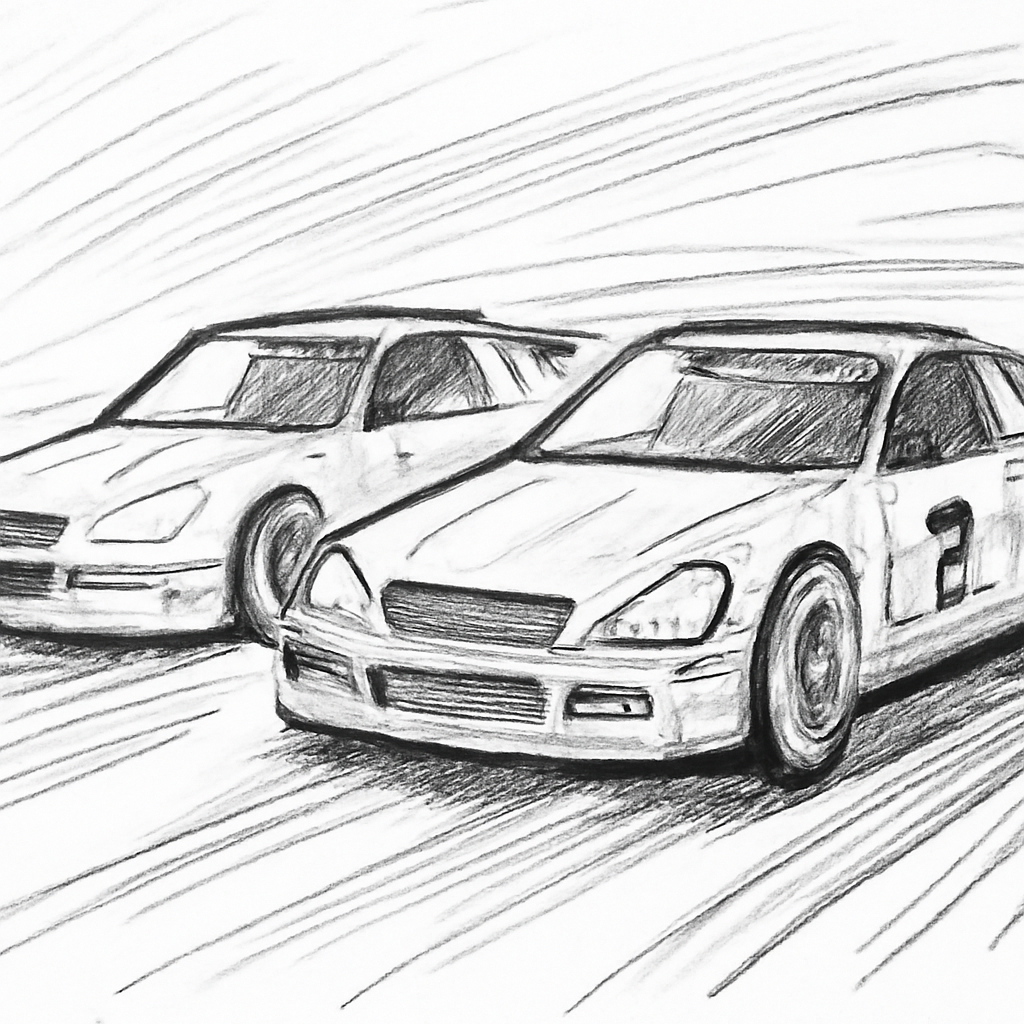

In [19]:
Image("wygenerowany_obrazek.png")

In [20]:
class HowIsCarDoing(BaseModel):
    car_is_moving: bool
    car_is_not_moving: bool
    car_is_black: bool
    car_is_destructed: bool
    car_is_dirty: bool
    car_is_clean: bool

generate_data_for_image(
    image_path="wygenerowany_obrazek.png",
    response_model=HowIsCarDoing
)

{'number_of_people': 0,
 'number_of_cats': 0,
 'number_of_dogs': 0,
 'allowed_for_children': True}